In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv("/content/SDOT_Collisions_Dataset.csv", low_memory=False)   # paste your copied path here
print(df.shape)

(262998, 64)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262998 entries, 0 to 262997
Data columns (total 64 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   OBJECTID                        262998 non-null  int64  
 1   SE_ANNO_CAD_DATA                262998 non-null  object 
 2   INCKEY                          262998 non-null  int64  
 3   COLDETKEY                       262998 non-null  int64  
 4   REPORTNO                        262998 non-null  object 
 5   STATUS                          262998 non-null  object 
 6   ADDRTYPE                        262998 non-null  object 
 7   INTKEY                          88620 non-null   float64
 8   LOCATION                        257941 non-null  object 
 9   EXCEPTRSNCODE                   13378 non-null   object 
 10  EXCEPTRSNDESC                   13378 non-null   object 
 11  PERSONCOUNT                     262998 non-null  int64  
 12  PEDCOUNT        

In [ ]:
display(df.describe())

,OBJECTID,INCKEY,COLDETKEY,INTKEY,PERSONCOUNT,PEDCOUNT,PEDCYLCOUNT,VEHCOUNT,INJURIES,SERIOUSINJURIES,...,SEGLANEKEY,CROSSWALKKEY,SEVERITYCODE,ADDR_SEGINTKEY,DIRIMPACTUNIT1CD,DIRIMPACTUNIT2CD,DIRPRIORUNIT1CD,DIRPRIORUNIT2CD,x,y
count,262998.000000,262998.000000,262998.000000,88620.000000,262998.000000,262998.000000,262998.000000,262998.000000,262998.000000,262998.000000,...,262998.000000,2.629980e+05,262618.000000,262998.000000,262997.000000,262997.000000,262997.000000,262997.000000,2.545890e+05,254589.000000
mean,131499.500000,179217.483977,179646.705336,38639.879982,2.141883,0.040993,0.028426,1.691108,0.174594,0.010110,...,227.470616,8.262310e+03,1.211768,27879.543160,3.306802,4.504215,3.377890,4.331669,1.271178e+06,229551.137446
std,75921.127386,114334.098188,114903.083879,56673.041903,1.503329,0.208573,0.167668,0.867018,0.481315,0.107303,...,3018.273278,6.645018e+04,0.461962,68003.906949,2.640379,3.307378,2.549131,3.237470,7.384379e+03,20644.390935
min,1.000000,1001.000000,1001.000000,23807.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000e+00,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.248147e+06,184059.089009
25%,65750.250000,82038.250000,82038.250000,28709.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000e+00,1.000000,9404.000000,1.000000,1.000000,1.000000,1.000000,1.266722e+06,213326.135695
50%,131499.500000,149358.500000,149378.500000,30132.000000,2.000000,0.000000,0.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000e+00,1.000000,15356.000000,3.000000,5.000000,3.000000,5.000000,1.271178e+06,228087.952798
75%,197248.750000,286092.250000,286952.250000,34108.000000,3.000000,0.000000,0.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000e+00,1.000000,29256.000000,5.000000,8.000000,5.000000,7.000000,1.276052e+06,245873.775280
max,262998.000000,394339.000000,395879.000000,933350.000000,93.000000,6.000000,3.000000,15.000000,4.000000,4.000000,...,525241.000000,5.239700e+06,4.000000,933350.000000,8.000000,9.000000,8.000000,9.000000,1.293052e+06,271525.414794


In [ ]:
# ------------------------------------------------------------------
# 1. Remove duplicate collision reports (same REPORTNO entered twice)
# ------------------------------------------------------------------
before = len(df)
df = df.drop_duplicates(subset="REPORTNO", keep="first")
print(f"Removed {before - len(df)} duplicate report numbers")

Removed 3 duplicate report numbers


In [ ]:
# ------------------------------------------------------------------
# 2. Remove rows with no severity (all have 0 injuries/fatalities and
#    cannot be classified)
# ------------------------------------------------------------------
before = len(df)
df = df[df["SEVERITYCODE"].notna()].copy()
print(f"Removed {before - len(df)} rows with missing severity")

Removed 380 rows with missing severity


In [ ]:
# ------------------------------------------------------------------
# 3. Date and time
#    INCDTTM holds the local date+time; ~23% of rows have a date only.
#    INCDATE carries an artificial 7/8 AM timestamp, so it is not used.
# ------------------------------------------------------------------
raw_dt = df["INCDTTM"].astype(str).str.strip()
dt_full = pd.to_datetime(raw_dt, format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
dt_date = pd.to_datetime(raw_dt, format="%m/%d/%Y", errors="coerce")
df["Has_Time"] = dt_full.notna()
df["Date"] = dt_full.fillna(dt_date).dt.normalize()
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%b")
df["Day_of_Week"] = df["Date"].dt.day_name()
df["Is_Weekend"] = df["Date"].dt.dayofweek >= 5
df["Hour"] = dt_full.dt.hour  # NaN when only a date was recorded
df["Complete_Year"] = df["Year"] <= 2025  # 2026 is a partial year
print(f"Rows with date only (no time): {(~df['Has_Time']).sum():,} -> Hour left blank")

Rows with date only (no time): 60,543 -> Hour left blank


In [ ]:
# ------------------------------------------------------------------
# 4. Severity (this file: 1 = property damage, 2 = injury,
#    3 = serious injury, 4 = fatal)
# ------------------------------------------------------------------
sev_map = {1: "Property Damage Only", 2: "Injury", 3: "Serious Injury", 4: "Fatal"}
df["SEVERITYCODE"] = df["SEVERITYCODE"].astype(int)
df["Severity"] = df["SEVERITYCODE"].map(sev_map)
df["Severe"] = df["SEVERITYCODE"].isin([3, 4]).astype(int)       # Vision Zero focus
df["Injury_or_Worse"] = (df["SEVERITYCODE"] >= 2).astype(int)

In [ ]:
# ------------------------------------------------------------------
# 5. Road-user flags
# ------------------------------------------------------------------
df["Pedestrian_Involved"] = (df["PEDCOUNT"] >= 1).astype(int)
df["Cyclist_Involved"] = (df["PEDCYLCOUNT"] >= 1).astype(int)
df["Vulnerable_User_Involved"] = ((df["PEDCOUNT"] + df["PEDCYLCOUNT"]) >= 1).astype(int)

In [ ]:
# ------------------------------------------------------------------
# 6. Contributing-factor flags
#    SPEEDING / INATTENTIONIND / PEDROWNOTGRNT are only ever "Y" or blank,
#    so blank means "not recorded as a factor" (1 = recorded, 0 = not).
#    UNDERINFL mixes Y/N/1/0; blank stays unknown.
# ------------------------------------------------------------------
for src, new in [("SPEEDING", "Speeding"), ("INATTENTIONIND", "Inattention"),
                 ("PEDROWNOTGRNT", "Ped_ROW_Not_Granted")]:
    df[new] = (df[src] == "Y").astype(int)
df["Under_Influence"] = df["UNDERINFL"].map({"Y": 1, "1": 1, "N": 0, "0": 0})  # NaN = unknown
df["Hit_Parked_Car"] = (df["HITPARKEDCAR"] == "Y").astype(int)

In [ ]:
# ------------------------------------------------------------------
# 7. Group condition fields into clean categories
#    Blank, "Unknown" and "Other" are combined into "Unknown/Other".
# ------------------------------------------------------------------
weather_map = {
    "Clear": "Clear", "Partly Cloudy": "Clear", "Overcast": "Overcast",
    "Raining": "Rain", "Snowing": "Snow/Ice", "Sleet/Hail/Freezing Rain": "Snow/Ice",
    "Blowing Snow": "Snow/Ice", "Fog/Smog/Smoke": "Fog/Other Visibility",
    "Blowing Sand/Dirt": "Fog/Other Visibility", "Severe Crosswind": "Fog/Other Visibility",
}
road_map = {
    "Dry": "Dry", "Wet": "Wet", "Standing Water": "Wet",
    "Ice": "Snow/Ice", "Snow/Slush": "Snow/Ice",
    "Sand/Mud/Dirt": "Debris/Oil", "Oil": "Debris/Oil",
}
light_map = {
    "Daylight": "Daylight", "Dawn": "Dawn/Dusk", "Dusk": "Dawn/Dusk",
    "Dark - Street Lights On": "Dark - Lit",
    "Dark - No Street Lights": "Dark - Unlit", "Dark - Street Lights Off": "Dark - Unlit",
    "Dark - Unknown Lighting": "Dark - Unknown Lighting",
}
df["Weather"] = df["WEATHER"].map(weather_map).fillna("Unknown/Other")
df["Road_Condition"] = df["ROADCOND"].map(road_map).fillna("Unknown/Other")
df["Light_Condition"] = df["LIGHTCOND"].map(light_map).fillna("Unknown/Other")

In [ ]:
# ------------------------------------------------------------------
# 8. Location fields
# ------------------------------------------------------------------
df["Address_Type"] = df["ADDRTYPE"].map({"B": "Block", "I": "Intersection", "A": "Alley"})
df["Junction_Type"] = df["JUNCTIONTYPE"].replace({"Unknown": np.nan}).fillna("Unknown")
df["Location"] = df["LOCATION"].str.strip().str.upper()
df["Collision_Type"] = df["COLLISIONTYPE"].fillna("Unknown")
df["Report_Source"] = df["Source description"].replace({
    "Police Traffic Collision Report": "Police",
    "Citizen Vehicle Collision Report": "Citizen"})

In [ ]:
# Convert WA State Plane North (EPSG:2926, US feet) to latitude/longitude
# (inverse Lambert Conformal Conic, GRS80) so the data maps in Tableau/Python.
def stateplane_to_latlon(x_ft, y_ft):
    a, f = 6378137.0, 1 / 298.257222101
    e = np.sqrt(2 * f - f * f)
    ft = 1200 / 3937
    phi1, phi2, phi0 = np.radians([47.5, 48 + 44 / 60, 47.0])
    lam0 = np.radians(-(120 + 50 / 60))
    fe, fn = 500000.0, 0.0
    m = lambda p: np.cos(p) / np.sqrt(1 - (e * np.sin(p)) ** 2)
    t = lambda p: np.tan(np.pi / 4 - p / 2) / ((1 - e * np.sin(p)) / (1 + e * np.sin(p))) ** (e / 2)
    n = (np.log(m(phi1)) - np.log(m(phi2))) / (np.log(t(phi1)) - np.log(t(phi2)))
    F = m(phi1) / (n * t(phi1) ** n)
    r0 = a * F * t(phi0) ** n
    x = x_ft * ft - fe
    y = r0 - (y_ft * ft - fn)
    r = np.sign(n) * np.sqrt(x ** 2 + y ** 2)
    tt = (r / (a * F)) ** (1 / n)
    theta = np.arctan2(x, y)
    lon = theta / n + lam0
    lat = np.pi / 2 - 2 * np.arctan(tt)
    for _ in range(6):
        lat = np.pi / 2 - 2 * np.arctan(tt * ((1 - e * np.sin(lat)) / (1 + e * np.sin(lat))) ** (e / 2))
    return np.degrees(lat), np.degrees(lon)

df["Latitude"], df["Longitude"] = stateplane_to_latlon(df["x"].values, df["y"].values)

In [ ]:
# ------------------------------------------------------------------
# 9. Keep only the analysis columns
# ------------------------------------------------------------------
keep = [
    "INCKEY", "REPORTNO", "Report_Source",
    "Date", "Year", "Month", "Month_Name", "Day_of_Week", "Is_Weekend", "Hour", "Has_Time",
    "Complete_Year",
    "SEVERITYCODE", "Severity", "Severe", "Injury_or_Worse",
    "PERSONCOUNT", "PEDCOUNT", "PEDCYLCOUNT", "VEHCOUNT",
    "INJURIES", "SERIOUSINJURIES", "FATALITIES",
    "Pedestrian_Involved", "Cyclist_Involved", "Vulnerable_User_Involved",
    "Speeding", "Under_Influence", "Inattention", "Ped_ROW_Not_Granted", "Hit_Parked_Car",
    "Weather", "Road_Condition", "Light_Condition",
    "Collision_Type", "SDOT_COLDESC", "ST_COLDESC",
    "Address_Type", "Junction_Type", "Location", "INTKEY",
    "Latitude", "Longitude",
]
clean = df[keep].rename(columns={
    "INCKEY": "Incident_Key", "REPORTNO": "Report_No", "SEVERITYCODE": "Severity_Code",
    "PERSONCOUNT": "Person_Count", "PEDCOUNT": "Ped_Count", "PEDCYLCOUNT": "Cyclist_Count",
    "VEHCOUNT": "Vehicle_Count", "INJURIES": "Injuries", "SERIOUSINJURIES": "Serious_Injuries",
    "FATALITIES": "Fatalities", "SDOT_COLDESC": "SDOT_Collision_Desc",
    "ST_COLDESC": "State_Collision_Desc", "INTKEY": "Intersection_Key",
})

In [ ]:
clean.to_csv("SDOT_Collisions_Clean.csv", index=False)
print(f"Clean data: {len(clean):,} rows x {clean.shape[1]} columns")

Clean data: 262,615 rows x 43 columns


In [ ]:
from google.colab import files
files.download("SDOT_Collisions_Clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df = pd.read_csv("SDOT_Collisions_Clean.csv", low_memory=False, parse_dates=["Date"])

print(f"Total collisions:        {len(df):,}")
print(f"Date range:              {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Severe collisions:       {df['Severe'].sum():,} ({df['Severe'].mean():.1%})")
print(f"Fatal collisions:        {(df['Severity'] == 'Fatal').sum():,}")
print(f"Total deaths:            {df['Fatalities'].sum():,}")
print(f"Total serious injuries:  {df['Serious_Injuries'].sum():,}")
print()
print(df["Severity"].value_counts())

Total collisions:        262,615
Date range:              2003-10-06 to 2026-10-18
Severe collisions:       5,022 (1.9%)
Fatal collisions:        541
Total deaths:            473
Total serious injuries:  2,659

Severity
Property Damage Only    212565
Injury                   45028
Serious Injury            4481
Fatal                      541
Name: count, dtype: int64


In [ ]:
full = df[(df["Year"] >= 2004) & (df["Year"] <= 2025)]   # 2003 and 2026 are partial years

In [ ]:
trend = full.groupby("Year").agg(
    total=("Severe", "size"),
    severe=("Severe", "sum"))
trend["pct_severe"] = (trend["severe"] / trend["total"] * 100).round(2)
print(trend)

      total  severe  pct_severe
Year                           
2004  15454     252        1.63
2005  16016     234        1.46
2006  15794     327        2.07
2007  15082     259        1.72
2008  14139     213        1.51
2009  13275     224        1.69
2010  11958     198        1.66
2011  12417     152        1.22
2012  12732     198        1.56
2013  12757     200        1.57
2014  13213     204        1.54
2015  14259     165        1.16
2016  13954     205        1.47
2017  12485     197        1.58
2018  12219     187        1.53
2019  11236     193        1.72
2020   7254     171        2.36
2021   8170     221        2.71
2022   7681     259        3.37
2023   7367     301        4.09
2024   6464     249        3.85
2025   5751     250        4.35


**Business question:** "Is Seattle on track to meet its Vision Zero goal of ending traffic deaths and serious injuries by 2030?"

**Answer:** No. Total collisions have fallen by nearly half, but severe collisions have risen since Vision Zero launched in 2015, and the share of crashes that are severe has nearly tripled.

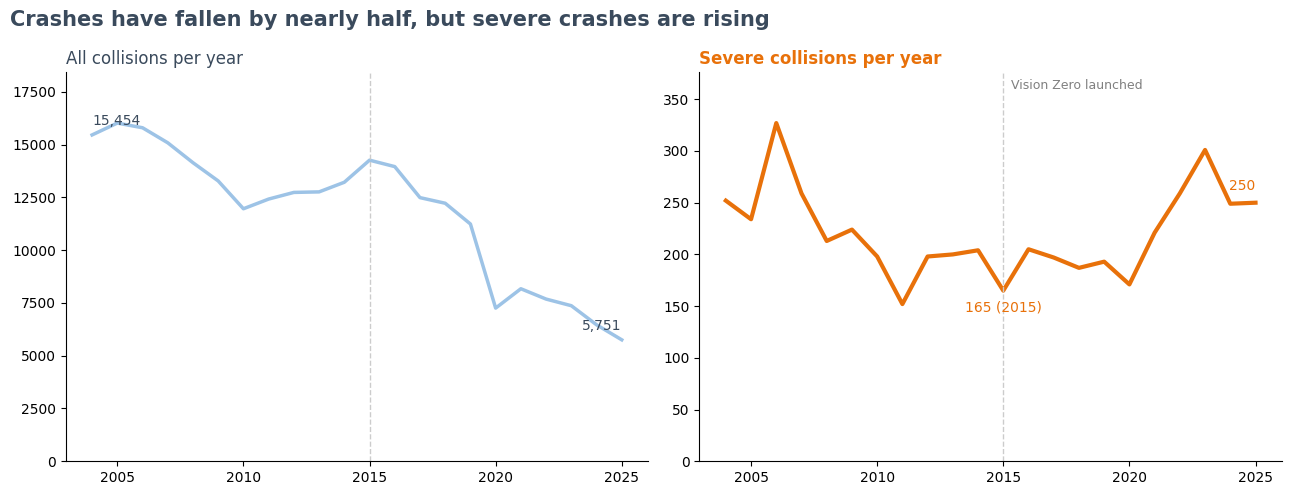

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: all collisions (soft blue, the context)
ax1.plot(trend.index, trend["total"], color="#9DC3E6", linewidth=2.5)
ax1.set_title("All collisions per year", loc="left", fontsize=12, color="#3A4A5C")
ax1.text(2004, trend.loc[2004, "total"] * 1.03, f"{trend.loc[2004, 'total']:,}", color="#3A4A5C")
ax1.text(2025, trend.loc[2025, "total"] * 1.08, f"{trend.loc[2025, 'total']:,}", color="#3A4A5C", ha="right")
ax1.set_ylim(0, trend["total"].max() * 1.15)

# Right: severe collisions (orange, the focus)
ax2.plot(trend.index, trend["severe"], color="#E8710A", linewidth=3)
ax2.set_title("Severe collisions per year", loc="left", fontsize=12, color="#E8710A", fontweight="bold")
ax2.text(2015, trend.loc[2015, "severe"] - 20, "165 (2015)", color="#E8710A", ha="center")
ax2.text(2025, trend.loc[2025, "severe"] + 12, "250", color="#E8710A", ha="right")
ax2.set_ylim(0, trend["severe"].max() * 1.15)

for ax in (ax1, ax2):
    ax.axvline(2015, color="#cccccc", linestyle="--", linewidth=1)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
ax2.text(2015.3, trend["severe"].max() * 1.1, "Vision Zero launched", color="gray", fontsize=9)

fig.suptitle("Crashes have fallen by nearly half, but severe crashes are rising",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color="#3A4A5C")
plt.tight_layout()
plt.show()

In [ ]:
recent = df[(df["Year"] >= 2016) & (df["Year"] <= 2025)]
timed = recent[recent["Has_Time"]]   # only rows with a recorded time

by_hour = timed.groupby("Hour").agg(total=("Severe", "size"), severe=("Severe", "sum"))
by_hour["pct_severe"] = (by_hour["severe"] / by_hour["total"] * 100).round(2)
print(by_hour)

      total  severe  pct_severe
Hour                           
0.0    1707      78        4.57
1.0    1533      77        5.02
2.0    1514      84        5.55
3.0     908      31        3.41
4.0     790      38        4.81
5.0    1027      34        3.31
6.0    1803      58        3.22
7.0    3176      66        2.08
8.0    4005      55        1.37
9.0    3796      73        1.92
10.0   3407      74        2.17
11.0   3669      73        1.99
12.0   4489      81        1.80
13.0   4396      94        2.14
14.0   4581     120        2.62
15.0   5033     130        2.58
16.0   5193     163        3.14
17.0   5270     178        3.38
18.0   4229     151        3.57
19.0   3400     115        3.38
20.0   3035     101        3.33
21.0   2764     124        4.49
22.0   2640     111        4.20
23.0   2121      73        3.44


**Business question:** "When should SDOT focus enforcement and safety campaigns?"

**Answer:** Two windows: the evening rush (3–9 PM), when the most severe crashes happen, and late night (9 PM–3 AM), when a crash is most likely to be severe.

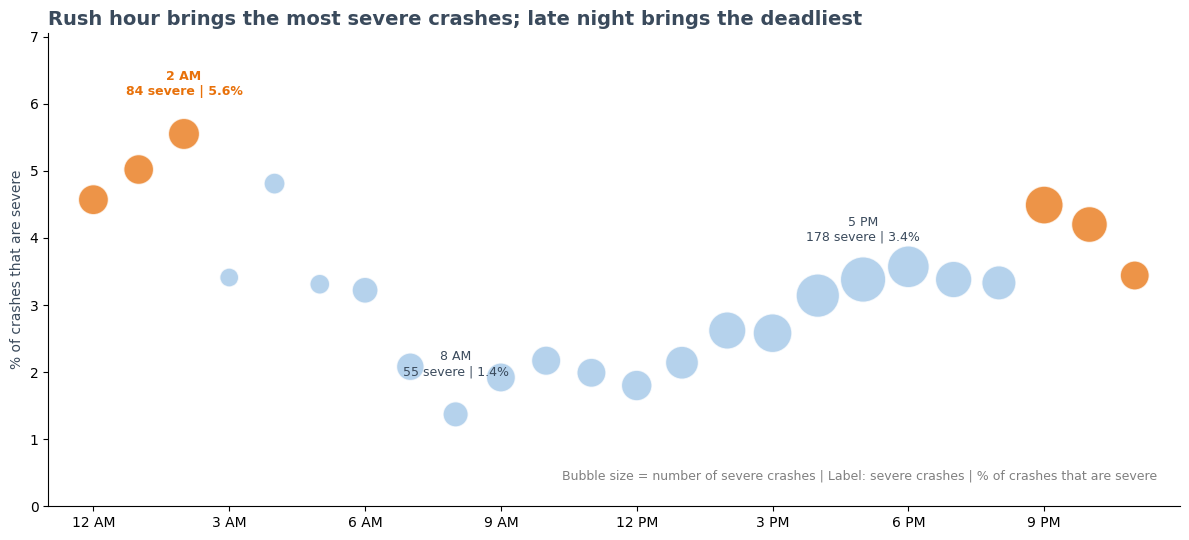

In [ ]:
hours = by_hour.index.astype(int)
night = [21, 22, 23, 0, 1, 2]
colors = ["#E8710A" if h in night else "#9DC3E6" for h in hours]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.scatter(hours, by_hour["pct_severe"], s=by_hour["severe"] * 6,
           color=colors, alpha=0.75, edgecolor="white", linewidth=1)

# Label the key bubbles
notes = {2: ("2 AM\n84 severe | 5.6%", "#E8710A"),
         17: ("5 PM\n178 severe | 3.4%", "#3A4A5C"),
         8: ("8 AM\n55 severe | 1.4%", "#3A4A5C")}
for h, (txt, c) in notes.items():
    y = by_hour.loc[float(h), "pct_severe"]
    ax.annotate(txt, (h, y), xytext=(0, 28), textcoords="offset points",
                ha="center", color=c, fontsize=9, fontweight="bold" if h == 2 else "normal")

ax.set_xticks(range(0, 24, 3))
ax.set_xticklabels(["12 AM", "3 AM", "6 AM", "9 AM", "12 PM", "3 PM", "6 PM", "9 PM"])
ax.set_xlim(-1, 24)
ax.set_ylim(0, by_hour["pct_severe"].max() + 1.5)
ax.set_ylabel("% of crashes that are severe", color="#3A4A5C")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

ax.text(23.5, 0.4, "Bubble size = number of severe crashes | Label: severe crashes | % of crashes that are severe",
        ha="right", color="gray", fontsize=9)
ax.set_title("Rush hour brings the most severe crashes; late night brings the deadliest",
             loc="left", fontsize=14, fontweight="bold", color="#3A4A5C")
plt.tight_layout()
plt.show()

**Business question:** "Which driver behaviors should SDOT target with enforcement and safety campaigns?"

**Answer:** Speeding first, then failure to yield to pedestrians, then impairment. Speed cameras, lower speed limits, and road designs that naturally slow drivers will have the biggest impact on deaths.

All crashes {'Speeding': 13.7, "Didn't stop for pedestrian": 7.9, 'Under the influence': 6.4, 'Multiple factors': 9.9, 'Inattention': 34.8, 'Hit parked car': 27.4}
Severe crashes {'Speeding': 34.0, "Didn't stop for pedestrian": 29.6, 'Under the influence': 9.6, 'Multiple factors': 9.2, 'Inattention': 12.5, 'Hit parked car': 5.1}


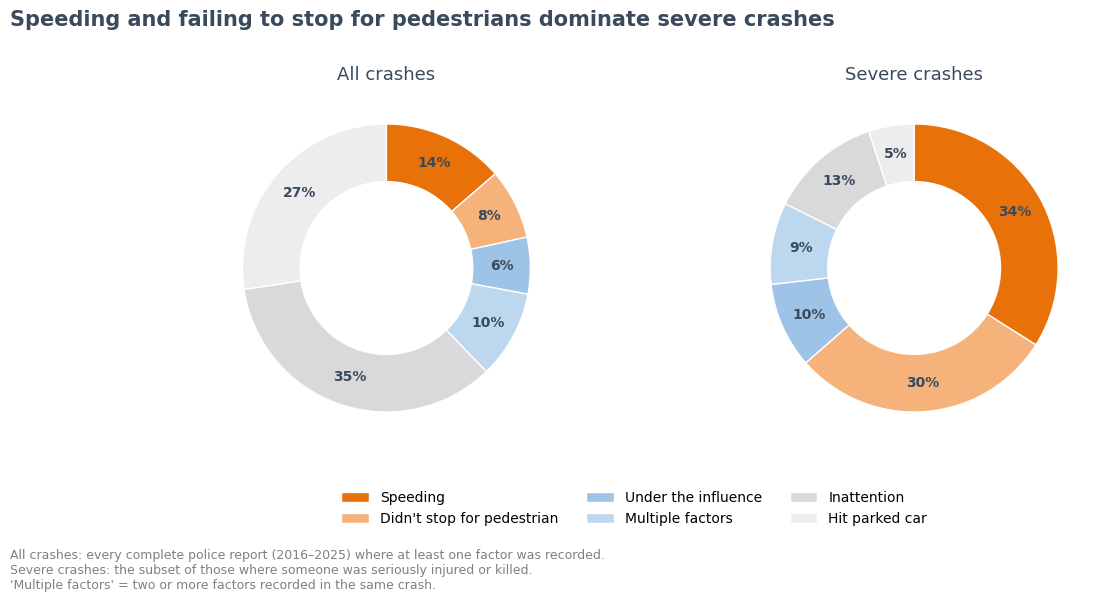

In [ ]:
r = df[(df["Year"] >= 2016) & (df["Year"] <= 2025)]
q = r[(r["Report_Source"] == "Police") & (r["Under_Influence"].notna())].copy()

cols = {"Speeding": "Speeding", "Ped_ROW_Not_Granted": "Didn't stop for pedestrian",
        "Under_Influence": "Under the influence", "Inattention": "Inattention",
        "Hit_Parked_Car": "Hit parked car"}

def factor(row):
    flagged = [label for col, label in cols.items() if row[col] == 1]
    if len(flagged) > 1: return "Multiple factors"
    if len(flagged) == 1: return flagged[0]
    return None

q["Factor"] = q.apply(factor, axis=1)
q = q[q["Factor"].notna()]

order = ["Speeding", "Didn't stop for pedestrian", "Under the influence",
         "Multiple factors", "Inattention", "Hit parked car"]
colors = ["#E8710A", "#F5B27A", "#9DC3E6", "#BDD7EE", "#D9D9D9", "#EDEDED"]

groups = [("All crashes", q), ("Severe crashes", q[q["Severe"] == 1])]
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, (title, sub) in zip(axes, groups):
    shares = sub["Factor"].value_counts(normalize=True).reindex(order).fillna(0) * 100
    print(title, shares.round(1).to_dict())
    wedges, _ = ax.pie(shares, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"width": 0.4, "edgecolor": "white"})
    for w, s in zip(wedges, shares):
        if s >= 5:
            ang = (w.theta2 + w.theta1) / 2
            x, y = 0.8 * np.cos(np.radians(ang)), 0.8 * np.sin(np.radians(ang))
            ax.text(x, y, f"{s:.0f}%", ha="center", va="center", fontsize=10,
                    color="#3A4A5C", fontweight="bold")
    ax.set_title(title, fontsize=13, color="#3A4A5C")

fig.suptitle("Speeding and failing to stop for pedestrians dominate severe crashes",
             x=0.02, ha="left", fontsize=15, fontweight="bold", color="#3A4A5C")

fig.legend(order, loc="lower center", bbox_to_anchor=(0.5, 0.10), ncol=3,
           frameon=False, fontsize=10)

fig.text(0.02, 0.01,
         "All crashes: every complete police report (2016–2025) where at least one factor was recorded.\n"
         "Severe crashes: the subset of those where someone was seriously injured or killed.\n"
         "'Multiple factors' = two or more factors recorded in the same crash.",
         ha="left", va="bottom", color="gray", fontsize=9)

plt.subplots_adjust(top=0.85, bottom=0.25, wspace=0.1)
plt.show()